# 04 — Efeitos e confusão

**Perguntas (enunciado §3.2):**
1. Qual o efeito de cada fator da 1ª experiência no retorno em 7 dias, com IC, em ordem de tamanho?
2. Quanto do efeito bruto é seleção (o perfil de quem chega), e quanto sobra depois do ajuste?
3. O GPT-4 faz voltar mais, comparando grupos semelhantes?
4. Uma semana em que o retorno caiu: mudou o perfil de quem chegou, ou a taxa dentro do perfil?

**Como ler** (o cálculo está em [etl/efeitos.py](../etl/efeitos.py), o mesmo código que a carga usa):

| Termo | Significado |
|---|---|
| Novato | Pessoa (IP) vista na sua 1ª sessão na base. Cada pessoa entra uma vez. Elegíveis: 2.219 (BDR-003, 006, 008) |
| n | Quantos novatos têm aquele nível do fator (ex.: celular, n = 706). Quanto menor o n, mais largo o IC |
| Taxa de retorno | % dos novatos do grupo que abriram nova sessão em até 7 dias |
| p.p. (ponto percentual) | Diferença entre duas taxas: de 30% para 20% = −10 p.p. |
| Referência | O grupo contra o qual cada nível é comparado (ex.: tema "tarefa", horário "tarde") |
| Bruto | Taxa do grupo − taxa da referência, sem nenhum ajuste |
| Ajustado | A mesma diferença, entre pessoas **iguais nos outros fatores** (tema, horário, idioma, dispositivo, estado e mês) |
| Seleção (confusão) | A parte do bruto que vem do perfil de quem tem o fator, e não do fator. **Seleção = bruto − ajustado** |
| Controle | Variável que entra no ajuste só para igualar os grupos e não vira achado (estado e mês) |
| IC 95% | Faixa onde o efeito real deve estar. Se o IC cruza o zero, o dado não separa o efeito de "nenhum efeito" |

**O ajuste** é uma regressão linear do retorno (1 = voltou, 0 = não voltou) com todos os fatores juntos. Num
resultado 0/1, o coeficiente de cada nível já é a diferença em p.p. contra a referência, com os outros fatores
fixos. O IC usa o erro-padrão robusto, o padrão para resultado 0/1.

**Fora do ajuste principal:** o volume da 1ª sessão. Ele é consequência da experiência (uma recusa encurta a
sessão), e controlar por ele esconderia parte do efeito. Ele entra só na sensibilidade (seção 4).

In [1]:
from estilo import AZUL, BRUTA, FUNDO, LARANJA, RAIZ, TINTA_2, TINTA_MUDA, VOLUME, aplicar  # põe etl/ no path

import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from efeitos import CONTROLES, FATORES, ROTULOS, VOLUME as VOLUME_SESSAO, ajustar, coeficiente, formula, preparar
from efeitos import tabela_efeitos, taxa_esperada
from estatistica import wilson
from primeira_experiencia import TEMAS, construir_primeira_experiencia

aplicar()
pd.set_option("display.width", 180)
warnings.filterwarnings("ignore", message="The inplace keyword")  # aviso interno do DuckDB → pandas

con = duckdb.connect()
con.execute("SET memory_limit = '3GB'; SET enable_progress_bar = false")
pe = construir_primeira_experiencia(con, BRUTA, str(TEMAS), volume_diario=VOLUME)
df = preparar(pe)
res = ajustar(df)
GERAL = df.y.mean()
FONTE = "Fonte: WildChat-1M, Brasil, 04/2023–04/2024 · etl/efeitos.py"
print(f"novatos: {int(res.nobs)} | retorno: {GERAL:.1%}")


def nome(nivel: object) -> str:
    return ROTULOS.get(nivel, str(nivel))

novatos: 2219 | retorno: 28.6%


## 1. O efeito de cada fator, em ordem de tamanho

,linha,n,bruto_pp,ajustado_pp,ic_inf,ic_sup
0,Conselho pessoal (tema),49,17.8,17.1,2.9,31.3
1,Tradução e reescrita (tema),110,10.8,8.2,-1.8,18.1
2,Manhã (6–11h) (horário),515,5.8,5.3,0.2,10.5
3,Noite (18–23h) (horário),734,3.0,3.1,-1.5,7.7
4,Outro (tema),70,-0.6,2.5,-8.7,13.6
5,Criativo e entretenimento (tema),292,2.7,2.4,-3.9,8.7
6,Inglês (idioma),454,1.7,1.5,-3.5,6.5
7,4º quartil (longa) (1ª resposta),555,2.5,0.3,-5.6,6.3
8,Programação e tecnologia (tema),301,-0.9,-2.6,-8.8,3.7
9,3º quartil (1ª resposta),553,-2.6,-2.9,-8.5,2.8


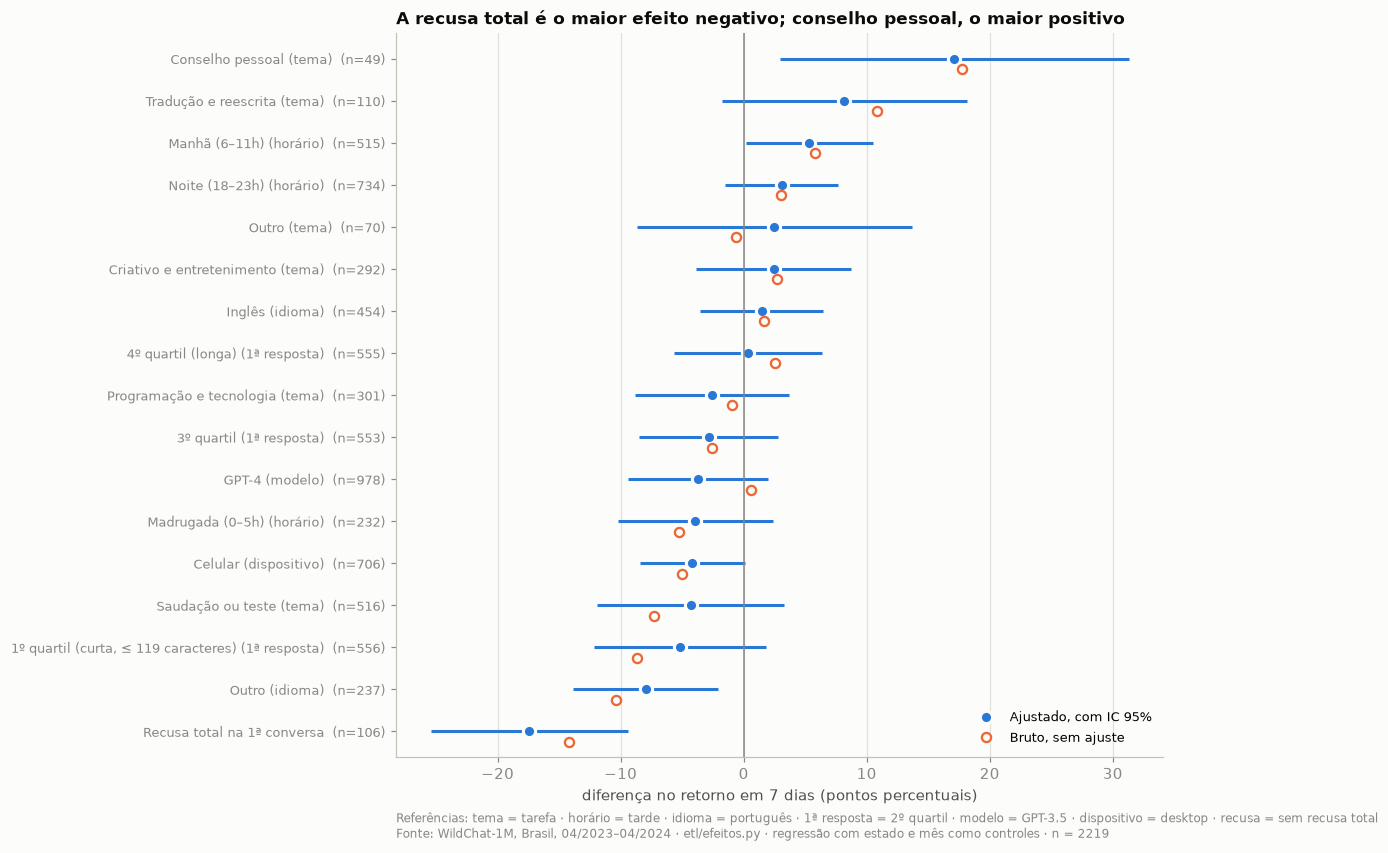

In [2]:
tab = tabela_efeitos(df, res)
CURTO = {"recusa_total": "recusa total", "tema_grupo": "tema", "faixa_horaria": "horário", "dispositivo": "dispositivo",
         "idioma_3": "idioma", "resposta_quartil": "1ª resposta", "familia_modelo": "modelo"}
tab["linha"] = ["Recusa total na 1ª conversa" if f == "recusa_total" else f"{nome(n)} ({CURTO[f]})"
                for f, n in zip(tab.fator, tab.nivel, strict=True)]
REFS = "Referências: tema = tarefa · horário = tarde · idioma = português · 1ª resposta = 2º quartil · " \
       "modelo = GPT-3.5 · dispositivo = desktop · recusa = sem recusa total"
tab = tab.sort_values("ajustado_pp", ascending=False).reset_index(drop=True)
display(tab[["linha", "n", "bruto_pp", "ajustado_pp", "ic_inf", "ic_sup"]].round(1))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(tab) + 1.4))
y = np.arange(len(tab))
ax.hlines(y, tab.ic_inf, tab.ic_sup, color=AZUL, lw=2)
ax.plot(tab.ajustado_pp, y, "o", color=AZUL, ms=8, mec=FUNDO, mew=2, label="Ajustado, com IC 95%")
ax.plot(tab.bruto_pp, y + 0.25, "o", color=LARANJA, ms=6, mfc=FUNDO, mew=1.5, label="Bruto, sem ajuste")
ax.axvline(0, color=TINTA_MUDA, lw=1)
ax.set_yticks(y, [f"{t}  (n={n})" for t, n in zip(tab.linha, tab.n, strict=True)], fontsize=8.5)
ax.set_ylim(len(tab) - 0.4, -0.6)
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("diferença no retorno em 7 dias (pontos percentuais)")
ax.set_title("A recusa total é o maior efeito negativo; conselho pessoal, o maior positivo")
ax.legend(loc="lower right", fontsize=8.5)
ax.annotate(f"{REFS}\n{FONTE} · regressão com estado e mês como controles · n = {int(res.nobs)}",
            xy=(0, -0.6 / len(tab) - 0.04),
            xycoords="axes fraction", fontsize=8, color=TINTA_MUDA, va="top")
plt.show()

**Conclusão:**
- **Recusa total na 1ª conversa: −17 p.p. (IC −25 a −9).** É o maior efeito, e o único negativo com IC longe do
  zero entre os fatores de conteúdo. Sobre uma base de 29%, quem leva recusa volta pouco mais da metade.
- **Conselho pessoal: +17 p.p. (IC +3 a +31), n = 49.** É positivo, mas a amostra é pequena.
- **Idioma "outro": −8 p.p.** e **manhã: +5 p.p.** contra a tarde ficam com IC fora do zero.
- **Saudação (−4), resposta curta (−5), celular (−4) e madrugada (−4)** apontam para baixo, mas o IC cruza o zero.
- **São 17 comparações.** Com IC de 95%, cerca de 1 delas pode passar do zero por acaso. A recusa passa com folga;
  conselho e manhã, por pouco.

## 2. Confusão: quanto do bruto era seleção

In [3]:
sel = tab.assign(selecao_pp=tab.bruto_pp - tab.ajustado_pp)
display(sel.loc[sel.selecao_pp.abs().sort_values(ascending=False).index,
                ["linha", "bruto_pp", "ajustado_pp", "selecao_pp"]].round(1).head(8))

,linha,bruto_pp,ajustado_pp,selecao_pp
10,GPT-4 (modelo),0.6,-3.7,4.3
14,"1º quartil (curta, ≤ 119 caracteres) (1ª respo...",-8.7,-5.2,-3.5
16,Recusa total na 1ª conversa,-14.2,-17.4,3.2
4,Outro (tema),-0.6,2.5,-3.1
13,Saudação ou teste (tema),-7.3,-4.3,-3.0
1,Tradução e reescrita (tema),10.8,8.2,2.6
15,Outro (idioma),-10.4,-8.0,-2.4
7,4º quartil (longa) (1ª resposta),2.5,0.3,2.2


**Conclusão:** a diferença entre o bruto e o ajustado é a parte do efeito que vinha do perfil.
- **GPT-4: de +0,6 para −3,7 p.p.** Sem ajuste, o GPT-4 parecia neutro. No mesmo mês e com o mesmo perfil, ele
  fica abaixo. A seção 3 mostra o passo a passo.
- **Saudação (−7 → −4), resposta curta (−9 → −5) e idioma "outro" (−10 → −8):** os três sinais se sobrepõem. A
  pessoa que só diz "oi" recebe uma resposta curta, e o detector de idioma erra na mensagem curta. O ajuste divide
  o efeito entre os três, e nenhum fica sozinho com IC longe do zero, exceto o idioma.
- **Recusa total: de −14 para −17 p.p.** O ajuste não reduz o efeito; ele aumenta. A recusa quase nunca cai numa
  saudação (1 de 106 casos), e a saudação já volta menos. Comparada com gente do mesmo tema, a recusa pesa mais.

## 3. GPT-4: comparar no mesmo mês

O GPT-4 não existe de jul. a out./2023 e domina a partir de jan./2024 (02_eda, seção 6). Na base inteira,
"GPT-4 × GPT-3.5" é quase "2024 × 2023". A comparação justa acontece **dentro do mesmo mês**, nos 6 meses em que os
dois modelos aparecem (10% a 90% de GPT-4). O mês como controle da regressão faz exatamente isso, e também iguala
o resto do perfil.

In [4]:
m = df.groupby("mes", observed=True).familia_modelo.apply(lambda s: (s == "gpt-4").mean())
mistos = m[(m > 0.1) & (m < 0.9)].index.tolist()
dm = df[df.mes.isin(mistos)]
mm = dm.groupby(["mes", "familia_modelo"], observed=True).y.agg(["size", "mean"]).unstack()
mes_a_mes = pd.DataFrame({
    "novatos GPT-3.5": mm[("size", "gpt-3.5")], "retorno GPT-3.5 (%)": 100 * mm[("mean", "gpt-3.5")],
    "novatos GPT-4": mm[("size", "gpt-4")], "retorno GPT-4 (%)": 100 * mm[("mean", "gpt-4")],
})
mes_a_mes["diferença (p.p.)"] = mes_a_mes["retorno GPT-4 (%)"] - mes_a_mes["retorno GPT-3.5 (%)"]
display(mes_a_mes.round(1))

n_mes = mes_a_mes["novatos GPT-3.5"] + mes_a_mes["novatos GPT-4"]
gpt4 = df.familia_modelo == "gpt-4"
gpt4_m = dm.familia_modelo == "gpt-4"
ef4 = coeficiente(res, "familia_modelo", "gpt-4")
passos = pd.DataFrame([
    ("Bruto, base inteira", 100 * (df.y[gpt4].mean() - df.y[~gpt4].mean()), ""),
    ("Bruto, só nos 6 meses com os dois", 100 * (dm.y[gpt4_m].mean() - dm.y[~gpt4_m].mean()), ""),
    ("Dentro do mesmo mês (média dos 6 meses, pelo nº de novatos)",
     float((mes_a_mes["diferença (p.p.)"] * n_mes).sum() / n_mes.sum()), ""),
    ("Mesmo mês e mesmo perfil (regressão da seção 1)", 100 * ef4[0], f"{100 * ef4[1]:.1f} a {100 * ef4[2]:+.1f}"),
], columns=["comparação", "GPT-4 − GPT-3.5 (p.p.)", "IC 95%"]).set_index("comparação")
display(passos.round(1))

,novatos GPT-3.5,retorno GPT-3.5 (%),novatos GPT-4,retorno GPT-4 (%),diferença (p.p.)
mes,,,,,
2023-05,226,30.1,137,21.2,-8.9
2023-04,57,38.6,72,41.7,3.1
2023-06,134,22.4,55,34.5,12.2
2023-11,180,28.3,42,21.4,-6.9
2023-12,41,17.1,76,30.3,13.2
2024-01,6,50.0,47,40.4,-9.6


,GPT-4 − GPT-3.5 (p.p.),IC 95%
comparação,,
"Bruto, base inteira",0.6,
"Bruto, só nos 6 meses com os dois",2.0,
"Dentro do mesmo mês (média dos 6 meses, pelo nº de novatos)",-1.0,
Mesmo mês e mesmo perfil (regressão da seção 1),-3.7,-9.4 a +2.0


**Conclusão:**
- Na base inteira, o GPT-4 fica **+0,6 p.p.** acima; nos 6 meses com os dois, **+2 p.p.** Dentro do mesmo mês, a
  vantagem some (**−1 p.p.**). Com o mês e o perfil iguais, fica em **−3,7 p.p. (IC −9,4 a +2,0)**.
- Mês a mês, o GPT-4 ganha em 3 meses e perde em 3. Não há padrão.
- **Não há evidência de que o GPT-4 faça voltar mais.** A vantagem bruta vinha do mês e do perfil: o GPT-4 se
  concentra em meses que já voltam mais (por exemplo, o lançamento, abr./2023).
- O IC é largo. A análise **não prova** que o GPT-4 é pior: ela descarta um ganho maior que +2 p.p.

## 4. Sensibilidade do efeito da recusa

A pergunta: o número da recusa muda se a conta mudar? Cada linha troca uma escolha e refaz o ajuste.

In [5]:
def trocar(col: str) -> list[str]:
    return [col if f == "recusa_total" else f for f in FATORES]


def linha(variante: str, r_, col: str = "recusa_total") -> dict:
    ef, lo, hi = (100 * v for v in coeficiente(r_, col, True))
    return {"variante": variante, "recusa_pp": ef, "ic_95": f"{lo:.1f} a {hi:.1f}"}


logit = smf.logit(formula(list(FATORES), list(CONTROLES)), data=df).fit(disp=0, cov_type="HC1", maxiter=100)
lg = logit.get_margeff(at="overall", dummy=True).summary_frame().loc["recusa_total[T.True]"]
sens = pd.DataFrame([
    linha("Principal (regressão linear)", res),
    linha("+ volume da 1ª sessão no ajuste", ajustar(df, controles=list(CONTROLES) + [VOLUME_SESSAO])),
    linha("Recusa pelo regex, não pelo LLM", ajustar(df, fatores=trocar("recusa_regex")), "recusa_regex"),
    linha("Recusa em qualquer conversa da 1ª sessão", ajustar(df, fatores=trocar("recusa_total_sessao")),
          "recusa_total_sessao"),
    {"variante": "Regressão logística (outro formato de modelo)", "recusa_pp": 100 * lg.iloc[0],
     "ic_95": f"{100 * lg.iloc[4]:.1f} a {100 * lg.iloc[5]:.1f}"},
]).set_index("variante")
display(sens.round(1))

,recusa_pp,ic_95
variante,,
Principal (regressão linear),-17.4,-25.4 a -9.4
+ volume da 1ª sessão no ajuste,-15.5,-23.4 a -7.7
"Recusa pelo regex, não pelo LLM",-15.8,-23.8 a -7.8
Recusa em qualquer conversa da 1ª sessão,-10.0,-18.0 a -2.0
Regressão logística (outro formato de modelo),-16.2,-22.9 a -9.4


**Conclusão:**
- **A recusa total fica entre −15,5 e −17,4 p.p.** com o volume da sessão no ajuste, com o regex no lugar do LLM e
  com a regressão logística. O efeito não depende do detector nem do formato do modelo.
- A regressão logística é o modelo feito para resultado sim/não. Ela dá quase o mesmo número que a linear
  (−16,2 × −17,4, com IC sobreposto), então a escolha da linear, mais fácil de ler, não muda a conclusão.
- Com a recusa contada em **qualquer** conversa da sessão, o efeito cai para cerca de −10 p.p. Isso confirma o
  BDR-010: quem abre mais conversas leva mais recusas e também volta mais, e a mistura dilui o efeito.
- O volume da sessão quase não muda a recusa (−17,4 → −15,5). Logo, a recusa não age só por encurtar a sessão:
  quem leva recusa volta menos mesmo com a mesma quantidade de respostas.

## 5. A semana atípica: 17/07/2023

O enunciado pede uma semana. A coorte semanal tem IC de ±15 p.p. (notebook 03), então a maioria das variações é
ruído. O critério: a semana cujo IC de Wilson não toca a média, com pelo menos 20 novatos, e com a vizinha
confirmando o movimento.

semanas: 55 | fora do IC: 6 (por acaso, esperadas ≈ 2.8)


,n,k,taxa,lo,hi
coorte_semana,,,,,
2023-04-03,9,6,66.7,35.4,87.9
2023-07-03,39,17,43.6,29.3,59.0
2023-07-17,33,3,9.1,3.1,23.6
2023-07-24,25,2,8.0,2.2,25.0
2024-01-15,11,7,63.6,35.4,84.8
2024-02-05,10,6,60.0,31.3,83.2


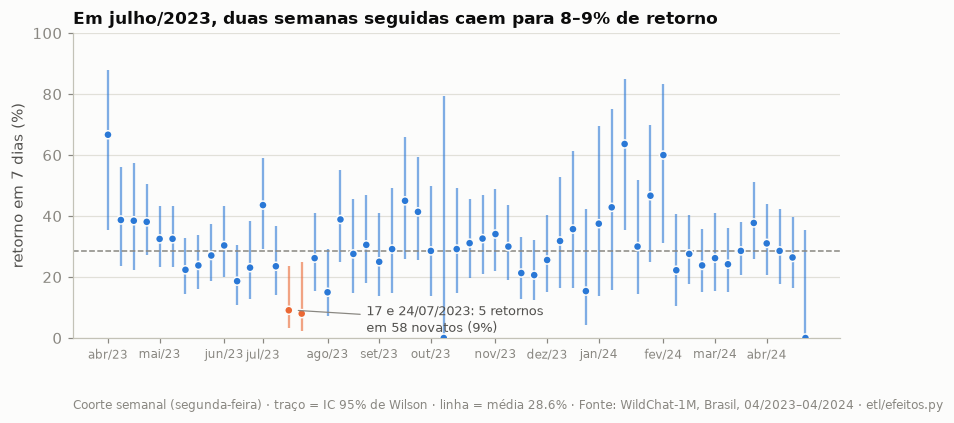

In [6]:
w = df.groupby("coorte_semana").agg(n=("y", "size"), k=("y", "sum"))
w["taxa"] = w.k / w.n
w[["lo", "hi"]] = [wilson(int(k), int(n)) for k, n in zip(w.k, w.n, strict=True)]
fora = w[(w.lo > GERAL) | (w.hi < GERAL)]
print(f"semanas: {len(w)} | fora do IC: {len(fora)} (por acaso, esperadas ≈ {0.05 * len(w):.1f})")
display(fora.assign(taxa=100 * fora.taxa, lo=100 * fora.lo, hi=100 * fora.hi).round(1))

ALVO = [pd.Timestamp("2023-07-17"), pd.Timestamp("2023-07-24")]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(w))
cor = [LARANJA if s in ALVO else AZUL for s in w.index]
ax.vlines(x, 100 * w.lo, 100 * w.hi, color=cor, lw=1.5, alpha=0.6)
ax.scatter(x, 100 * w.taxa, c=cor, s=28, zorder=3, edgecolors=FUNDO, linewidths=1)
ax.axhline(100 * GERAL, color=TINTA_MUDA, ls="--", lw=1)
i0 = list(w.index).index(ALVO[0])
ax.annotate("17 e 24/07/2023: 5 retornos\nem 58 novatos (9%)", (i0 + 0.5, 100 * w.taxa.iloc[i0]), xytext=(i0 + 6, 2),
            fontsize=8.5, color=TINTA_2, arrowprops={"arrowstyle": "-", "color": TINTA_MUDA, "lw": 0.8})
marcas = [i for i, s in enumerate(w.index) if s.day <= 7]
MESES = "jan fev mar abr mai jun jul ago set out nov dez".split()
ax.set_xticks(marcas, [f"{MESES[w.index[i].month - 1]}/{w.index[i]:%y}" for i in marcas], fontsize=8)
ax.set_ylabel("retorno em 7 dias (%)")
ax.set_ylim(0, 100)
ax.set_title("Em julho/2023, duas semanas seguidas caem para 8–9% de retorno")
ax.annotate(f"Coorte semanal (segunda-feira) · traço = IC 95% de Wilson · linha = média {100 * GERAL:.1f}% · {FONTE}",
            xy=(0, -0.2), xycoords="axes fraction", fontsize=8, color=TINTA_MUDA, va="top")
plt.show()

### Mudou o perfil ou mudou a taxa?

**A conta.** Cada pessoa das duas semanas recebe a taxa de retorno normal do seu grupo no resto da base (por
exemplo, a taxa de quem estreou com saudação). A média dá a **taxa esperada pelo perfil**: o retorno que as
semanas teriam com o público que chegou e o comportamento de sempre.
- **Efeito do perfil** = taxa esperada − média do resto da base. Mede se chegou um público diferente.
- **Efeito da taxa** = taxa observada − taxa esperada. Mede se o mesmo público voltou menos.

In [7]:
no_alvo = df.coorte_semana.isin(ALVO)
alvo, resto = df[no_alvo], df[~no_alvo]
k, n = int(alvo.y.sum()), len(alvo)
obs, media = k / n, resto.y.mean()
lo_, hi_ = wilson(k, n)
print(f"17 e 24/07/2023: {k} retornos em {n} novatos = {obs:.1%} (IC {lo_:.1%}–{hi_:.1%}) | resto da base: {media:.1%}")

PERFIS = {"tema": ["tema_grupo"], "dispositivo": ["dispositivo"], "idioma": ["idioma_3"], "horário": ["faixa_horaria"],
          "recusa total": ["recusa_total"], "tamanho da 1ª resposta": ["resposta_quartil"], "estado": ["estado_grupo"],
          "tema + dispositivo + horário": ["tema_grupo", "dispositivo", "faixa_horaria"]}


def decompor(cols: list[str]) -> dict:
    esp = taxa_esperada(alvo, resto, cols)
    return {"taxa esperada (%)": 100 * esp, "efeito do perfil (p.p.)": 100 * (esp - media),
            "efeito da taxa (p.p.)": 100 * (obs - esp)}


dec = pd.DataFrame({rot: decompor(cols) for rot, cols in PERFIS.items()}).T.rename_axis("perfil por")
display(dec.round(1))

perfil = pd.DataFrame(
    [(rot, 100 * alvo[c].eq(v).mean(), 100 * resto[c].eq(v).mean())
     for rot, c, v in [("% saudação", "tema_grupo", "saudacao_teste"), ("% tarefa", "tema_grupo", "tarefa_conhecimento"),
                       ("% celular", "dispositivo", "mobile"), ("% idioma outro", "idioma_3", "outro"),
                       ("% recusa total", "recusa_total", True), ("% GPT-4", "familia_modelo", "gpt-4")]],
    columns=["", "semanas 17 e 24/07", "resto da base"],
).set_index("")
display(perfil.round(0))

17 e 24/07/2023: 5 retornos em 58 novatos = 8.6% (IC 3.7%–18.6%) | resto da base: 29.2%


,taxa esperada (%),efeito do perfil (p.p.),efeito da taxa (p.p.)
perfil por,,,
tema,29.1,-0.0,-20.5
dispositivo,29.6,0.4,-20.9
idioma,28.6,-0.5,-20.0
horário,29.2,0.0,-20.5
recusa total,28.8,-0.3,-20.2
tamanho da 1ª resposta,28.9,-0.3,-20.2
estado,29.8,0.6,-21.2
tema + dispositivo + horário,29.4,0.3,-20.8


,semanas 17 e 24/07,resto da base
,,
% saudação,21.0,23.0
% tarefa,48.0,39.0
% celular,24.0,32.0
% idioma outro,16.0,11.0
% recusa total,7.0,5.0
% GPT-4,0.0,45.0


### Só no Brasil, ou no serviço inteiro?

Se o perfil não explica, a causa está fora da pessoa. Duas checagens com a base **global** (todos os países):
o volume diário e o retorno de todos os novatos do mundo nas mesmas semanas. A base global não entra na análise;
ela só testa se o movimento é do Brasil ou do serviço.

In [8]:
vol = con.execute(f"""
    SELECT CASE WHEN dia_utc < DATE '2023-07-20' THEN '1) 01–19/07' ELSE '2) 20/07–20/08' END AS periodo,
           round(avg(conversas)) AS conversas_por_dia_mundo
    FROM read_parquet('{RAIZ / "data" / "raw" / "wildchat_volume_diario.parquet"}')
    WHERE dia_utc BETWEEN DATE '2023-07-01' AND DATE '2023-08-20' GROUP BY 1 ORDER BY 1
""").df()
display(vol)
GLOBAL = RAIZ / "data" / "raw" / "wildchat-1m"
if GLOBAL.exists():
    # Definição simplificada (só para a tendência), igual para os dois lados: usuário = IP; país = o da 1ª conversa;
    # retorno = outra conversa entre 1h e 7 dias depois.
    glob = con.execute(f"""
        WITH c AS (SELECT hashed_ip, timestamp AS ts, country FROM read_parquet('{GLOBAL}/*.parquet')),
        f AS (SELECT hashed_ip, min(ts) AS t0, arg_min(country, ts) AS pais FROM c GROUP BY 1),
        r AS (SELECT f.hashed_ip, f.t0, f.pais = 'Brazil' AS br,
                     bool_or(c.ts > f.t0 + INTERVAL 1 HOUR AND c.ts <= f.t0 + INTERVAL 7 DAY) AS voltou
              FROM f JOIN c USING (hashed_ip) GROUP BY 1, 2, 3)
        SELECT date_trunc('week', t0)::DATE AS semana,
               count(*) FILTER (br) AS novatos_brasil, round(100 * avg(voltou::INT) FILTER (br), 1) AS retorno_brasil_pct,
               count(*) FILTER (NOT br) AS novatos_resto, round(100 * avg(voltou::INT) FILTER (NOT br), 1) AS retorno_resto_pct
        FROM r WHERE t0 >= TIMESTAMP '2023-06-19' AND t0 < TIMESTAMP '2023-08-21' GROUP BY 1 ORDER BY 1
    """).df()
    display(glob)
else:
    print("base global ausente (data/raw/wildchat-1m): rode etl/download.py para esta checagem")

,periodo,conversas_por_dia_mundo
0,1) 01–19/07,2825.0
1,2) 20/07–20/08,1947.0


,semana,novatos_brasil,retorno_brasil_pct,novatos_resto,retorno_resto_pct
0,2023-06-19,41,14.6,4190,21.6
1,2023-06-26,41,12.2,3204,25.7
2,2023-07-03,39,35.9,4340,24.6
3,2023-07-10,53,22.6,3994,20.4
4,2023-07-17,34,5.9,3506,20.3
5,2023-07-24,24,8.3,3441,20.4
6,2023-07-31,43,18.6,3391,21.6
7,2023-08-07,40,12.5,3238,21.3
8,2023-08-14,38,28.9,3003,21.4


**Conclusão da semana atípica:**
- **Semana de 17/07/2023: 9% de retorno (3 de 33).** A semana seguinte (24/07) repete o movimento: 8% (2 de 25).
  Juntas: 5 retornos em 58 novatos, **8,6% (IC 3,7–18,6%)**. O IC fica longe da média de 29%.
- **O perfil não mudou.** Por qualquer perfil (tema, dispositivo, idioma, horário, recusa, resposta, estado ou os
  três primeiros juntos), a taxa esperada fica entre 28,6% e 29,8%, igual à média. O efeito do perfil fica
  abaixo de 1 p.p.; o efeito da taxa é de **cerca de −20 p.p.** Não há GPT-4 nessas semanas, como em todo o
  período de jul. a out./2023.
- **O acaso explica mal.** Das 55 semanas, 6 ficam fora do IC, e cerca de 3 ficariam por acaso. Mas aqui são duas
  semanas **seguidas**, com 58 pessoas, e o IC das duas juntas não chega a 19%.
- **O resto do mundo não caiu junto.** Com a mesma definição simplificada, o retorno fora do Brasil fica em
  ~20% nessas semanas, como nas vizinhas, enquanto o Brasil cai. O volume global cai 31% a partir de 20/07 e não
  volta, mas o retorno global não acompanha. Logo, a queda é **local, do Brasil**, e não do serviço.
- **O dado não diz a causa.** Uma hipótese é o recesso escolar de julho no Brasil (estudantes testam e não
  voltam). Janeiro, também de férias, teve o movimento oposto, então a hipótese é fraca. Ela pode ser testada
  com julho/2024 nos dados do produto.
- **Para o cliente:** a queda foi da taxa, não do perfil, e só no Brasil. Um alerta de retorno semanal fora do IC,
  com o perfil da semana ao lado, separa os dois casos no mesmo dia.

## 6. O que a análise prova e o que não prova

**Prova (dentro desta base):**
- Quem leva recusa total na 1ª conversa volta menos, cerca de 17 p.p., mesmo comparado a quem tem o mesmo tema,
  horário, idioma, dispositivo, estado e mês. O efeito resiste a 4 variantes.
- A vantagem bruta do GPT-4 é seleção: comparando no mesmo mês, ela desaparece.
- A queda de julho/2023 é de taxa, não de perfil, e não aparece no resto do mundo.

**Não prova:**
- **Causa.** O dado é observacional. Uma variável não observada (por exemplo, pedidos que o assistente recusa
  são de pessoas que não voltariam de qualquer jeito) pode explicar parte do efeito da recusa. Só um teste A/B
  (por exemplo, uma política de recusa mais branda num grupo sorteado) mede a causa.
- **Que o GPT-4 é pior.** O IC vai de −9,4 a +2,0 p.p.
- **Efeitos pequenos.** Com 2.219 novatos, um efeito real de 2–3 p.p. não aparece.
- **Retorno real.** O usuário é o IP. IP dinâmico e IP compartilhado distorcem a contagem (risco 1, caso do Rio).

**Candidatos aos 3 achados do relatório:**
1. A recusa total na estreia custa ~17 p.p. de retorno → revisar a política de recusa nos temas em que ela mais
   aparece (criativo, tarefa, programação), e medir com um teste A/B.
2. Metade dos retornos acontece em até 6 horas (02_eda) → a estreia e as horas seguintes decidem o retorno.
3. O modelo mais caro não traz mais retorno, comparando no mesmo mês → não usar o GPT-4 como alavanca de
   retenção sem um teste.

## 7. A tabela que a carga grava para o dashboard (`resultado_efeitos`)

In [9]:
saida = tab.assign(metodo="regressao_linear_hc1", n_modelo=int(res.nobs))[
    ["fator", "nivel", "referencia", "n", "bruto_pp", "ajustado_pp", "ic_inf", "ic_sup", "metodo", "n_modelo"]]
display(saida.round(1))

,fator,nivel,referencia,n,bruto_pp,ajustado_pp,ic_inf,ic_sup,metodo,n_modelo
0,tema_grupo,conselho_pessoal,tarefa_conhecimento,49,17.8,17.1,2.9,31.3,regressao_linear_hc1,2219
1,tema_grupo,traducao_reescrita,tarefa_conhecimento,110,10.8,8.2,-1.8,18.1,regressao_linear_hc1,2219
2,faixa_horaria,manha,tarde,515,5.8,5.3,0.2,10.5,regressao_linear_hc1,2219
3,faixa_horaria,noite,tarde,734,3.0,3.1,-1.5,7.7,regressao_linear_hc1,2219
4,tema_grupo,outro,tarefa_conhecimento,70,-0.6,2.5,-8.7,13.6,regressao_linear_hc1,2219
5,tema_grupo,criativo_entretenimento,tarefa_conhecimento,292,2.7,2.4,-3.9,8.7,regressao_linear_hc1,2219
6,idioma_3,ingles,portugues,454,1.7,1.5,-3.5,6.5,regressao_linear_hc1,2219
7,resposta_quartil,Q4,Q2,555,2.5,0.3,-5.6,6.3,regressao_linear_hc1,2219
8,tema_grupo,programacao_tecnologia,tarefa_conhecimento,301,-0.9,-2.6,-8.8,3.7,regressao_linear_hc1,2219
9,resposta_quartil,Q3,Q2,553,-2.6,-2.9,-8.5,2.8,regressao_linear_hc1,2219
